# Praktikum 2 - Support Vector Regression (SVR)

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 06:** Regresi

### Tujuan Praktikum:
1. Memahami penerapan **Support Vector Regression (SVR)** untuk relasi data non-linier.
2. Menerapkan penskalaan fitur (*Feature Scaling*) menggunakan `StandardScaler` pada variabel independen dan dependen.
3. Memprediksi estimasi gaji untuk tingkat posisi 6.5 (`Level = 6.5`).
4. Mengevaluasi performa model SVR menggunakan metrik MAE, MSE, RMSE, dan $R^2$.

## Langkah 1 s.d. 3 - Import Library dan Baca Data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data_path = r'..\Dataset\Posisi_gaji.csv'

dataset = pd.read_csv(data_path)
print('Dimensi data:', dataset.shape)
dataset

Dimensi data: (10, 3)


,Posisi,Level,Gaji
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


## Langkah 4 - Pemisahan Variabel Bebas (X) dan Variabel Target (y)

In [2]:
X = dataset.iloc[:, 1:2].values  # Kolom Level (2D array)
y = dataset.iloc[:, 2].values    # Kolom Gaji (1D array)
print('X (Level):\n', X.flatten())
print('y (Gaji):\n', y)

X (Level):
 [ 1  2  3  4  5  6  7  8  9 10]
y (Gaji):
 [  45000   50000   60000   80000  110000  150000  200000  300000  500000
 1000000]


## Langkah 5 - Penskalaan Fitur (Feature Scaling)

In [3]:
sc_X = StandardScaler()
sc_y = StandardScaler()

X_scaled = sc_X.fit_transform(X)
y_scaled = sc_y.fit_transform(y.reshape(-1, 1)).flatten()

print('X setelah scaling:\n', X_scaled.flatten())
print('y setelah scaling:\n', y_scaled)

X setelah scaling:
 [-1.5666989  -1.21854359 -0.87038828 -0.52223297 -0.17407766  0.17407766
  0.52223297  0.87038828  1.21854359  1.5666989 ]
y setelah scaling:
 [-0.72004253 -0.70243757 -0.66722767 -0.59680786 -0.49117815 -0.35033854
 -0.17428902  0.17781001  0.88200808  2.64250325]


## Langkah 6 - Fitting Model SVR (Kernel RBF)

In [4]:
regressor = SVR(kernel='rbf')
regressor.fit(X_scaled, y_scaled)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


## Langkah 7 - Prediksi Gaji untuk Tingkat Posisi 6.5

In [5]:
posisi_pred = np.array([[6.5]])
posisi_pred_scaled = sc_X.transform(posisi_pred)
gaji_pred_scaled = regressor.predict(posisi_pred_scaled)
gaji_pred = sc_y.inverse_transform(gaji_pred_scaled.reshape(-1, 1))

print(f'Prediksi Gaji untuk Tingkat Posisi 6.5: Rp {gaji_pred[0][0]:,.2f}')

Prediksi Gaji untuk Tingkat Posisi 6.5: Rp 170,370.02


## Langkah 8 - Visualisasi Kurva Regresi SVR

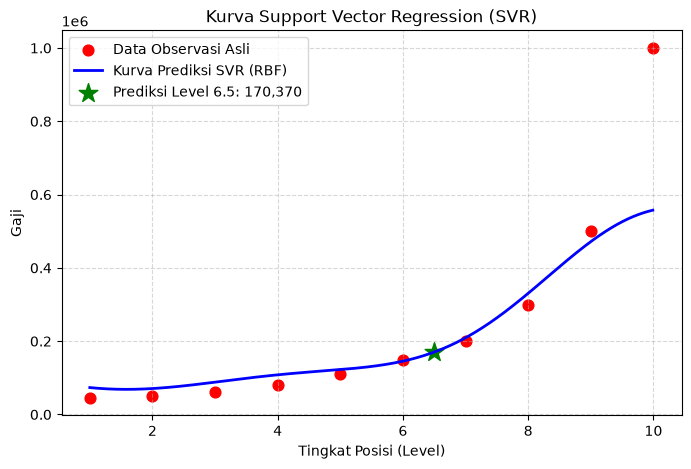

In [6]:
X_grid = np.arange(float(np.min(X)), float(np.max(X)), 0.01).reshape(-1, 1)
X_grid_scaled = sc_X.transform(X_grid)
y_grid_pred_scaled = regressor.predict(X_grid_scaled)
y_grid_pred = sc_y.inverse_transform(y_grid_pred_scaled.reshape(-1, 1))

plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='red', label='Data Observasi Asli', s=60)
plt.plot(X_grid, y_grid_pred, color='blue', linewidth=2, label='Kurva Prediksi SVR (RBF)')
plt.scatter(6.5, gaji_pred[0][0], color='green', marker='*', s=200, label=f'Prediksi Level 6.5: {gaji_pred[0][0]:,.0f}')
plt.title('Kurva Support Vector Regression (SVR)')
plt.xlabel('Tingkat Posisi (Level)')
plt.ylabel('Gaji')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Langkah 9 - Evaluasi Metrik Model SVR

In [7]:
y_pred_scaled = regressor.predict(X_scaled)
mae = mean_absolute_error(y_scaled, y_pred_scaled)
mse = mean_squared_error(y_scaled, y_pred_scaled)
rmse = np.sqrt(mse)
r2 = r2_score(y_scaled, y_pred_scaled)

print('=== Metrik Evaluasi Model SVR (Skala Standard) ===')
print(f'MAE      : {mae:.4f}')
print(f'MSE      : {mse:.4f}')
print(f'RMSE     : {rmse:.4f}')
print(f'R-squared: {r2:.4f}')

=== Metrik Evaluasi Model SVR (Skala Standard) ===
MAE      : 0.2230
MSE      : 0.2484
RMSE     : 0.4984
R-squared: 0.7516
